In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

customers = pd.read_csv("E:\CODING_ALL\Data Analytics\projrcts\RetailIQ\data\Cleaned csv\cleaned_customers.csv")
sales = pd.read_csv("E:\CODING_ALL\Data Analytics\projrcts\RetailIQ\data\Cleaned csv\cleaned_sales.csv")
items = pd.read_csv("E:\CODING_ALL\Data Analytics\projrcts\RetailIQ\data\Cleaned csv\cleaned_orders.csv")
rfm = pd.read_csv("customer_rfm_segments.csv")
kmeans = pd.read_csv("customer_kmeans_segments.csv")

sales["order_date"] = pd.to_datetime(sales["order_date"])

eligible_sales = sales[
    sales["order_status"].fillna("").str.lower() != "cancelled"
].copy()

eligible_items = items.merge(
    eligible_sales[["order_id", "customer_id"]],
    on="order_id",
    how="inner"
)

print("Eligible orders:", eligible_sales["order_id"].nunique())
print("Customers in RFM:", rfm["customer_id"].nunique())
print("Customers in K-Means:", kmeans["customer_id"].nunique())

Eligible orders: 129718
Customers in RFM: 24876
Customers in K-Means: 25000


In [2]:
# Order-level sales
order_metrics = eligible_items.groupby(
    ["customer_id", "order_id"]
).agg(
    order_value=("net_sales", "sum"),
    order_profit=("profit", "sum")
).reset_index()

customer_metrics = order_metrics.groupby("customer_id").agg(
    monetary_value=("order_value", "sum"),
    frequency=("order_id", "nunique"),
    total_profit=("order_profit", "sum"),
    avg_order_value=("order_value", "mean")
).reset_index()

# Recency based on the latest eligible order date
last_purchase = eligible_sales.groupby("customer_id")["order_date"].max()
reference_date = sales["order_date"].max() + pd.Timedelta(days=1)

customer_metrics["recency_days"] = (
    reference_date -
    customer_metrics["customer_id"].map(last_purchase)
).dt.days

# Return rate: proportion of eligible orders marked returned/refunded
eligible_sales["is_returned"] = (
    eligible_sales["return_status"].fillna("").str.lower()
    .isin(["returned", "refunded"])
)

return_metrics = eligible_sales.groupby("customer_id").agg(
    eligible_orders=("order_id", "nunique"),
    returned_orders=("is_returned", "sum")
).reset_index()

return_metrics["return_rate"] = (
    return_metrics["returned_orders"] /
    return_metrics["eligible_orders"]
)

customer_metrics = customer_metrics.merge(
    return_metrics[["customer_id", "return_rate"]],
    on="customer_id",
    how="left"
)

customer_metrics.head()

,customer_id,monetary_value,frequency,total_profit,avg_order_value,recency_days,return_rate
0,CUST-000001,9469.55,8,3734.08,1183.693750,7,0.125000
1,CUST-000002,18479.69,10,9326.12,1847.969000,283,0.200000
2,CUST-000003,8268.66,7,4148.37,1181.237143,210,0.142857
3,CUST-000004,11092.52,6,3685.02,1848.753333,55,0.166667
4,CUST-000005,10063.97,8,4021.66,1257.996250,413,0.000000


In [3]:
def evaluate_segments(segment_df, segment_col, segment_name):
    data = segment_df[
        ["customer_id", segment_col]
    ].merge(
        customer_metrics,
        on="customer_id",
        how="inner"
    )

    summary = data.groupby(segment_col).agg(
        customers=("customer_id", "nunique"),
        avg_spending=("monetary_value", "mean"),
        median_spending=("monetary_value", "median"),
        avg_frequency=("frequency", "mean"),
        avg_recency_days=("recency_days", "mean"),
        avg_return_rate=("return_rate", "mean"),
        total_profit=("total_profit", "sum"),
        avg_profit_per_customer=("total_profit", "mean")
    )

    total_profit = data["total_profit"].sum()

    summary["profit_contribution_pct"] = (
        summary["total_profit"] / total_profit * 100
        if total_profit != 0 else np.nan
    )

    summary["customer_pct"] = (
        summary["customers"] / summary["customers"].sum() * 100
    )

    print(f"\n{segment_name} segment evaluation")
    display(summary.round(2))

    return data, summary


rfm_data, rfm_summary = evaluate_segments(
    rfm, "customer_group", "RFM"
)

kmeans_data, kmeans_summary = evaluate_segments(
    kmeans, "cluster_label", "K-Means"
)


RFM segment evaluation


,customers,avg_spending,median_spending,avg_frequency,avg_recency_days,avg_return_rate,total_profit,avg_profit_per_customer,profit_contribution_pct,customer_pct
customer_group,,,,,,,,,,
Customers at risk of inactivity,4269,8534.27,8074.40,6.17,515.27,0.07,15479786.08,3626.09,20.28,17.16
High-value loyal customers,4067,12185.45,11441.81,7.86,61.06,0.07,20757324.18,5103.84,27.20,16.35
Inactive customers,4261,2869.05,2870.10,2.70,742.60,0.07,5293505.59,1242.32,6.94,17.13
Potential loyalists,4766,9124.03,8001.06,6.43,152.59,0.07,18516678.31,3885.16,24.26,19.16
Recent customers,2663,4625.16,4208.03,3.34,66.72,0.07,5101695.10,1915.77,6.68,10.71
Regular / needs attention,4850,5378.63,5099.32,4.19,312.00,0.07,11171015.99,2303.30,14.64,19.50



K-Means segment evaluation


,customers,avg_spending,median_spending,avg_frequency,avg_recency_days,avg_return_rate,total_profit,avg_profit_per_customer,profit_contribution_pct,customer_pct
cluster_label,,,,,,,,,,
Cluster 0,4232,6534.20,6039.26,4.85,356.83,0.30,12747778.85,3012.24,16.70,17.01
Cluster 1,3477,1907.74,1990.23,2.76,541.29,0.01,2912995.56,837.79,3.82,13.98
Cluster 2,10177,7745.46,6990.13,5.10,418.99,0.02,33142217.79,3256.58,43.43,40.91
Cluster 3,6990,9584.09,8946.59,6.82,53.53,0.05,27517013.05,3936.63,36.05,28.10


In [5]:
def compare_segments(data, segment_col):
    metrics = [
        "monetary_value",
        "frequency",
        "recency_days",
        "return_rate",
        "total_profit"
    ]

    results = []

    for metric in metrics:
        groups = [
            group[metric].dropna().values
            for _, group in data.groupby(segment_col)
        ]
        groups = [g for g in groups if len(g) > 0]

        if len(groups) >= 2:
            test = stats.kruskal(*groups)
            results.append({
                "metric": metric,
                "kruskal_statistic": test.statistic,
                "p_value": test.pvalue
            })

    result_df = pd.DataFrame(results)

    # Adjust for testing five metrics
    if not result_df.empty:
        result_df["significant_after_bonferroni"] = (
            result_df["p_value"] < 0.05 / len(result_df)
        )

    return result_df


print("RFM significance tests")
display(compare_segments(rfm_data, "customer_group").round(4))

print("K-Means significance tests")
display(compare_segments(kmeans_data, "cluster_label").round(4))

RFM significance tests


,metric,kruskal_statistic,p_value,significant_after_bonferroni
0,monetary_value,15214.3439,0.0,True
1,frequency,18141.8872,0.0,True
2,recency_days,17602.7675,0.0,True
3,return_rate,403.3787,0.0,True
4,total_profit,14120.0985,0.0,True


K-Means significance tests


,metric,kruskal_statistic,p_value,significant_after_bonferroni
0,monetary_value,9772.8353,0.0,True
1,frequency,8042.9105,0.0,True
2,recency_days,12829.5523,0.0,True
3,return_rate,15330.7147,0.0,True
4,total_profit,8687.0302,0.0,True


<Figure size 1000x500 with 0 Axes>

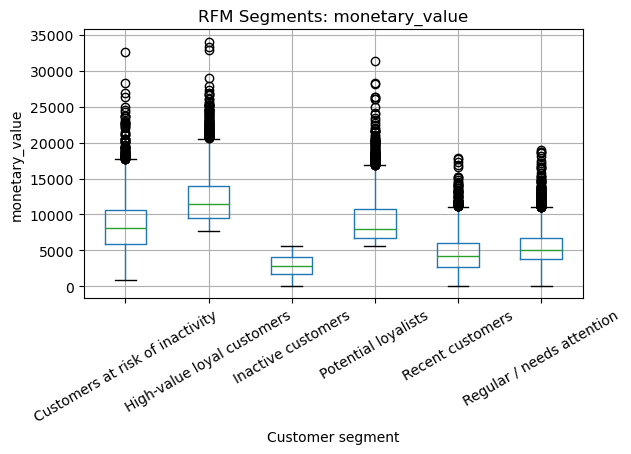

<Figure size 1000x500 with 0 Axes>

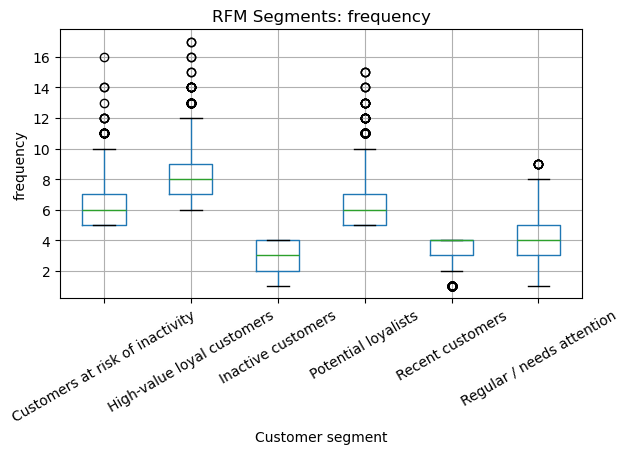

<Figure size 1000x500 with 0 Axes>

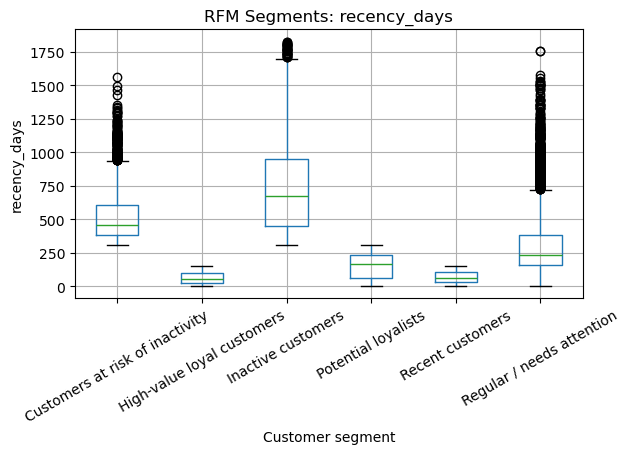

<Figure size 1000x500 with 0 Axes>

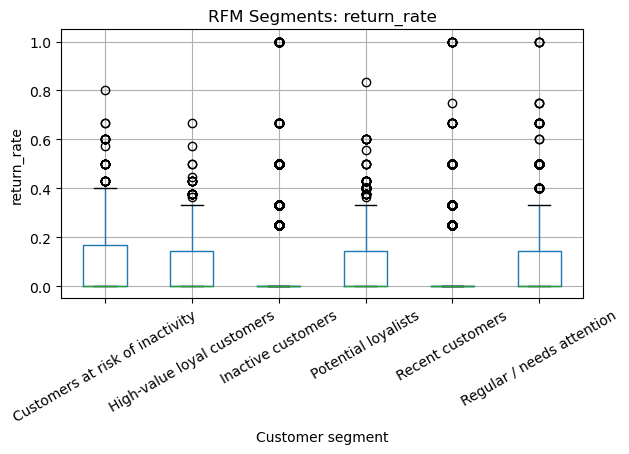

<Figure size 1000x500 with 0 Axes>

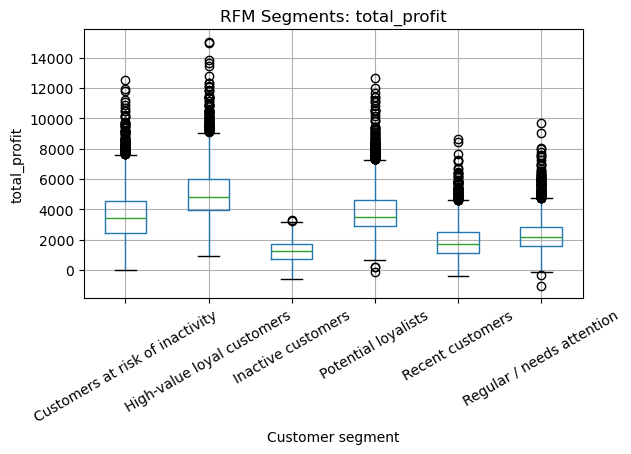

In [6]:
metrics_to_plot = [
    "monetary_value",
    "frequency",
    "recency_days",
    "return_rate",
    "total_profit"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(10, 5))
    rfm_data.boxplot(column=metric, by="customer_group", rot=30)
    plt.title(f"RFM Segments: {metric}")
    plt.suptitle("")
    plt.xlabel("Customer segment")
    plt.ylabel(metric)
    plt.tight_layout()
    plt.show()